# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Lunas, Bryce Enrico
- _Student No._: 2024-01596
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

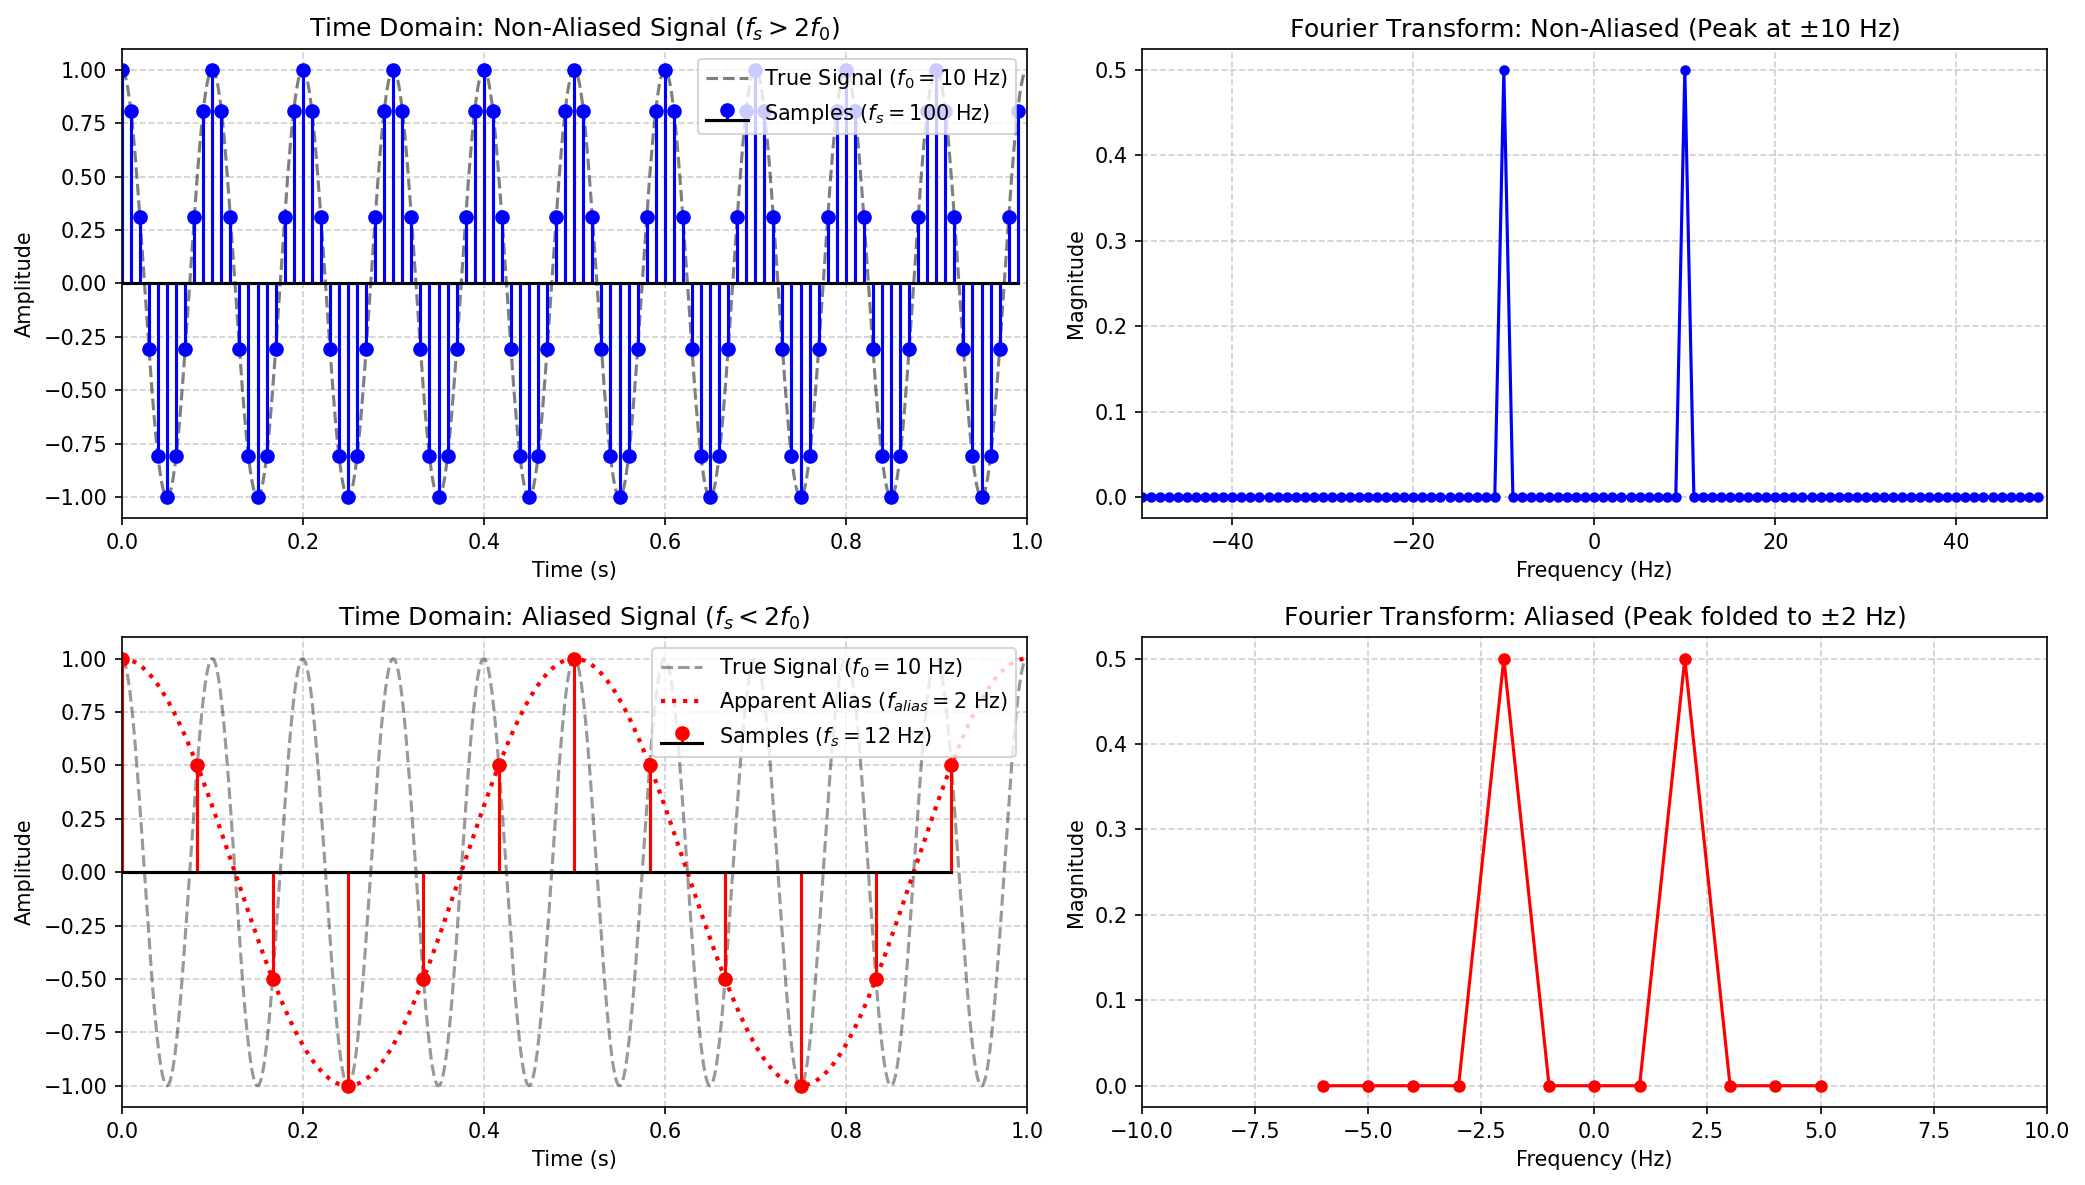

In [40]:
from IPython.display import Image

Image('aliasing_report.png')

*Figure 1: Comparison between the original clean composite signal and the reconstructed signal after Hanning windowing, FFT threshold filtering ($>3000$), and inverse FFT recovery.*

### Report discussion

**Problem 1:**
The Fourier transform of a Gaussian is also a Gaussian, with width proportional to 1/σ: increasing σ (a wider signal in time) makes the spectrum narrower and taller, while decreasing σ (a sharper signal) makes it broader and lower. This is the time-frequency trade-off, since a signal cannot be narrow in both domains at once. The phase is zero because the signal is real and even.

**Problem 2:** 
Lowering $N$ decreases the observation duration $T = N \cdot dt$, coarsening the frequency resolution ($\Delta f = 1/T$) and reducing the coherent FFT processing gain ($\propto \sqrt{N}$), which broadens the signal peaks and lowers their amplitude relative to the noise floor. While signal recovery remains possible for moderate values of $N$, thresholding fails when $N$ becomes too small because random Gaussian noise spikes submerge and distort the signal peaks. The lower limit for reliable recovery occurs around $N \approx 500\text{–}1000$ samples ($T \approx 0.1\text{–}0.2\text{ s}$), constrained by Rayleigh's frequency resolution limit ($\Delta f \le 50\text{ Hz}$) needed to resolve the adjacent $180\text{ Hz}$ and $230\text{ Hz}$ components and the minimum SNR required for thresholding.

**Problem 3:** 
The report figure demonstrates the Nyquist–Shannon sampling theorem using a $f_0 = 10\text{ Hz}$ pure cosine signal. In the top row ($f_s = 100\text{ Hz} > 2 f_0$), uniform sampling captures sufficient discrete points per cycle, allowing the Fourier transform to accurately resolve true peaks at $f = \pm 10\text{ Hz}$ without distortion. In the bottom row ($f_s = 12\text{ Hz} < 2 f_0$), the sampling frequency falls below the Nyquist threshold ($20\text{ Hz}$), causing undersampling where discrete samples inadvertently lie on a false, lower-frequency wave ($2\text{ Hz}$). Consequently, the Fourier transform folds the $10\text{ Hz}$ component into the Nyquist interval $[-6, 6]\text{ Hz}$, producing an aliased spectrum centered at $f_{\text{alias}} = |10 - 12| = 2\text{ Hz}$.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

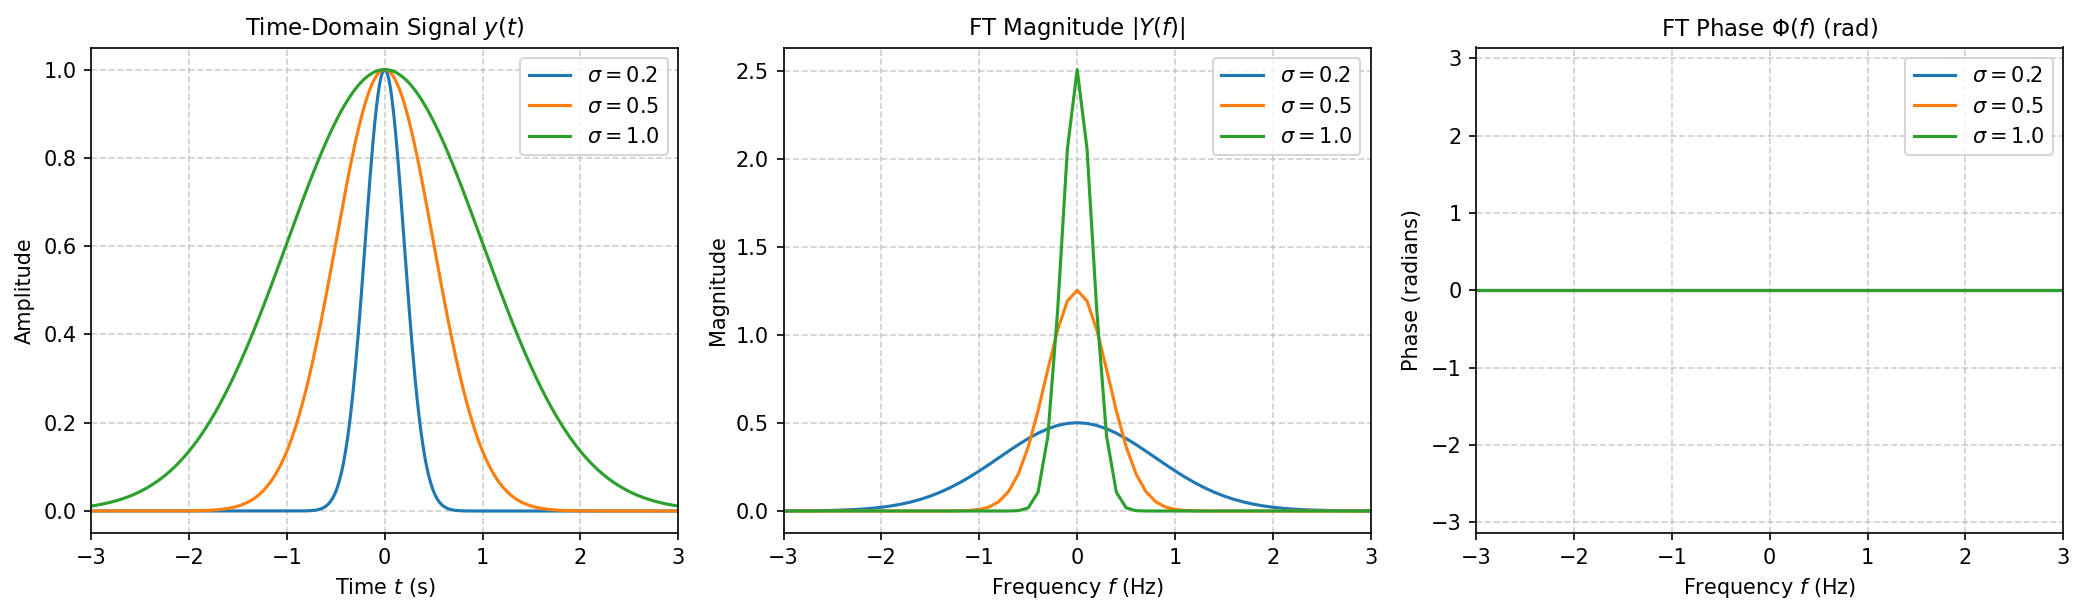

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import math

def explore_gaussian_ft():
  # 1. Grid and sampling parameters
  N = 1000  # Number of sample points
  dt = 0.01  # Time step (seconds)
  T = N * dt  # Total duration
  t = np.linspace(-T / 2, T / 2, N, endpoint=False)  # Centered time array

  # Frequency grid (Hz)
  freqs = np.fft.fftfreq(N, d=dt)
  freqs_shifted = np.fft.fftshift(freqs)

  sigmas = [0.2, 0.5, 1.0]

  fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), dpi=150)

  for sigma in sigmas:
    # Time-domain Gaussian signal
    y = np.exp(-(t**2) / (2 * sigma**2))
      
    Y = np.fft.fft(np.fft.ifftshift(y)) * dt
    Y_shifted = np.fft.fftshift(Y)

    mag = np.abs(Y_shifted)
    phase = np.angle(Y_shifted)
    phase[mag < 1e-4] = 0.0 

    axs[0].plot(t, y, label=rf'$\sigma = {sigma}$')
    axs[1].plot(freqs_shifted, mag, label=rf'$\sigma = {sigma}$')
    axs[2].plot(freqs_shifted, phase, label=rf'$\sigma = {sigma}$')

  axs[0].set_title('Time-Domain Signal $y(t)$', fontsize=11)
  axs[0].set_xlabel('Time $t$ (s)')
  axs[0].set_ylabel('Amplitude')
  axs[0].set_xlim(-3, 3)
  axs[0].grid(True, linestyle='--', alpha=0.6)
  axs[0].legend(frameon=True)

  axs[1].set_title('FT Magnitude $|Y(f)|$', fontsize=11)
  axs[1].set_xlabel('Frequency $f$ (Hz)')
  axs[1].set_ylabel('Magnitude')
  axs[1].set_xlim(-3, 3)
  axs[1].grid(True, linestyle='--', alpha=0.6)
  axs[1].legend(frameon=True)

  axs[2].set_title(r'FT Phase $\Phi(f)$ (rad)', fontsize=11)
  axs[2].set_xlabel('Frequency $f$ (Hz)')
  axs[2].set_ylabel('Phase (radians)')
  axs[2].set_xlim(-3, 3)
  axs[2].set_ylim(-np.pi, np.pi)
  axs[2].grid(True, linestyle='--', alpha=0.6)
  axs[2].legend(frameon=True)

  plt.tight_layout()
  plt.savefig('ft_waveforms.png', bbox_inches='tight')
  plt.show()


if __name__ == '__main__':
  explore_gaussian_ft()

**Problem 1: Code Summary**

I wrote a code that computes and visualizes the Fast Fourier Transform (FFT) of a Gaussian signal across varying widths to analyze its magnitude and phase response in frequency space. A centered grid combined with `np.fft.ifftshift` is used to maintain zero-phase symmetry at t-0, while multiplying by the sample spacing scales the discrete FFT to approximate the continuous Fourier integral. The 1x3 subplot layout separates the signal, magnitude, and phase responses to clearly illustrate the time-frequency uncertainty principle without visual clutter.

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [22]:
import matplotlib.pyplot as plt
import numpy as np

In [23]:
N = 25000
dt = 0.0002  # Spacing of 0.0002 s gives sampling frequency f_s = 5000 Hz
t_ = np.arange(N) * dt
freqs = [130, 230, 180]
phase = [np.pi / 3, np.pi / 4, np.pi / 6]

signal_original = np.sum(
    [np.cos(2 * np.pi * f * t_ + p) for f, p in zip(freqs, phase)], axis=0
)

(0.0, 0.3)

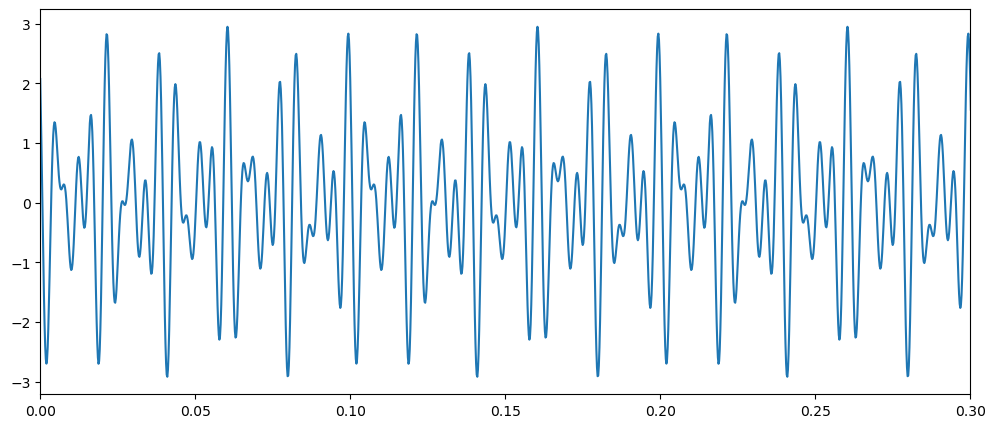

In [25]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, signal_original)
ax.set_xlim(0, 0.3)

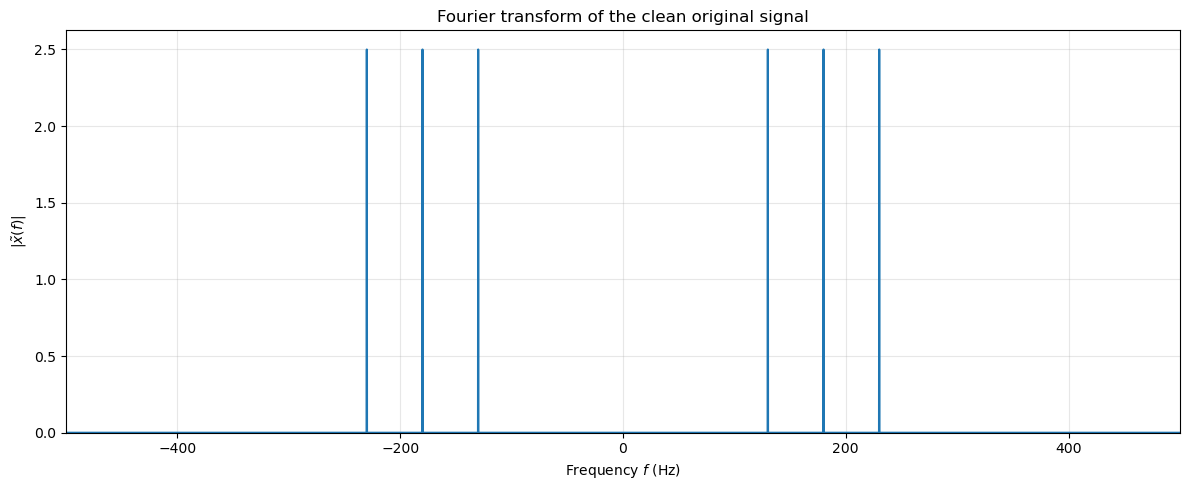

In [31]:
freqs = np.fft.fftshift(np.fft.fftfreq(N, dt))          # Hz, centred on 0
clean_ft = np.fft.fftshift(np.fft.fft(signal_original)) * dt   # dt -> continuous-FT scaling

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(freqs, np.abs(clean_ft))
ax.set(title='Fourier transform of the clean original signal',
       xlabel='Frequency $f$ (Hz)', ylabel=r'$|\tilde{x}(f)|$',
       xlim=(-500, 500), ylim=(0, None))
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [12]:
rng = np.random.default_rng()

mean = 0
std = 2

noise = rng.normal(loc=mean, scale=std, size=len(t_))
noisy_data = signal_original + noise * 5

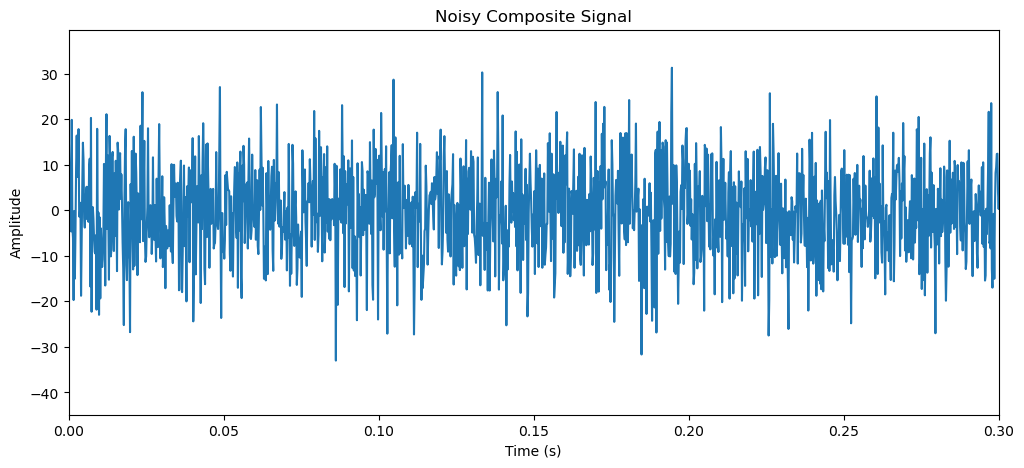

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, noisy_data)
ax.set_xlim(0, 0.3)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude')
ax.set_title('Noisy Composite Signal')
plt.show()

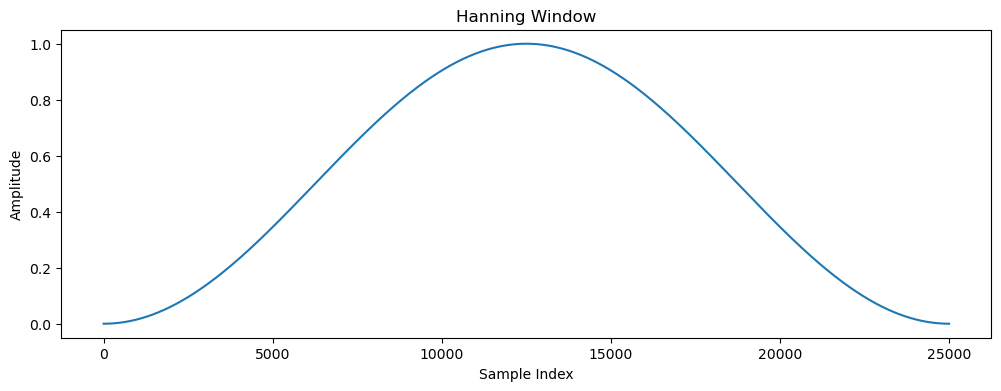

In [14]:
window = np.hanning(len(noisy_data))

plt.figure(figsize=(12, 4))
plt.plot(window)
plt.title('Hanning Window')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.show()

In [15]:
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

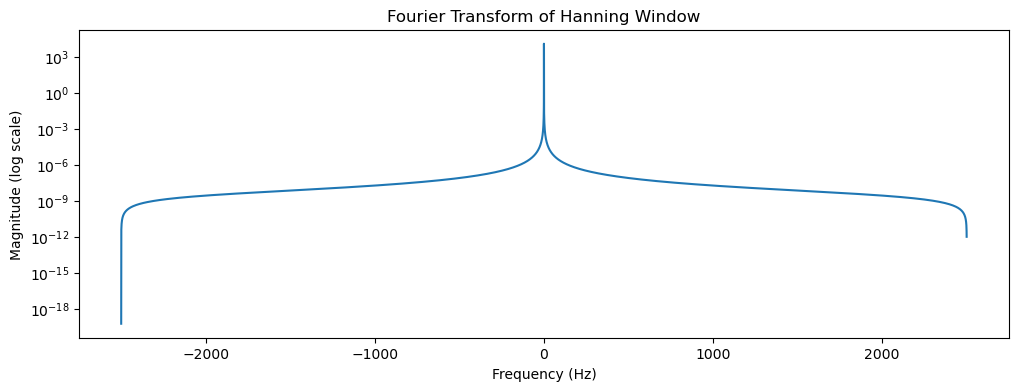

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')
plt.title('Fourier Transform of Hanning Window')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (log scale)')
plt.show()

In [17]:
noisyFourier = np.fft.fft(noisy_data * window)

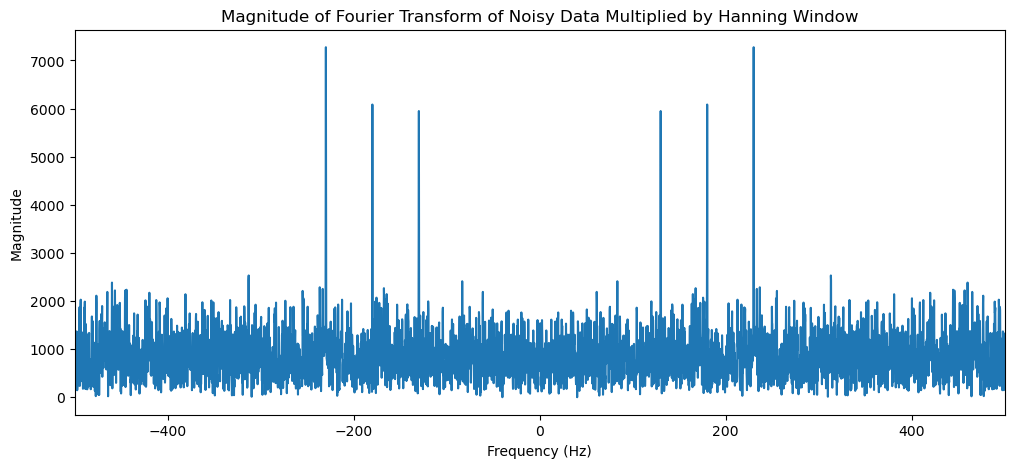

In [18]:
noisySigPeaks = np.abs(np.fft.fftshift(noisyFourier))
noisySigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(noisySigFreqs, noisySigPeaks)
ax.set_xlim(-500, 500)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Magnitude')
ax.set_title(
    'Magnitude of Fourier Transform of Noisy Data Multiplied by Hanning'
    ' Window'
)
plt.show()

In [19]:
threshold = 3000
cleanedFourier = noisyFourier.copy()
cleanedFourier[np.abs(noisyFourier) < threshold] = 0

In [20]:
recovered_windowed = np.fft.ifft(cleanedFourier).real

window_safe = np.where(window > 1e-3, window, np.nan)
recoveredSignal = recovered_windowed / window_safe

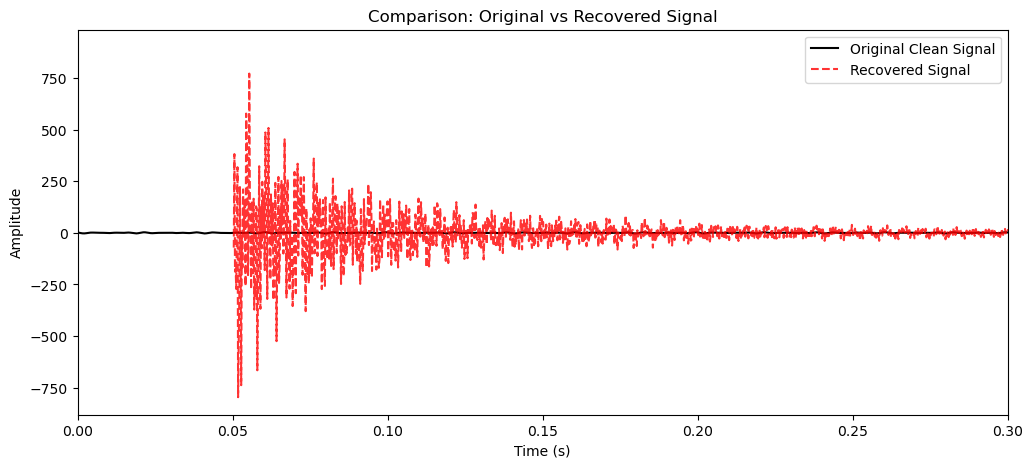

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, signal_original, label='Original Clean Signal', color='black')
ax.plot(
    t_,
    recoveredSignal,
    label='Recovered Signal',
    color='red',
    linestyle='--',
    alpha=0.8,
)
ax.set_xlim(0, 0.3)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude')
ax.set_title('Comparison: Original vs Recovered Signal')
ax.legend()
plt.show()

**Problem 2: Code Summary**

I wrote this code which isolates a multi-component sinusoidal signal from heavy Gaussian noise by applying a Hanning window and frequency-domain threshold filtering before performing an inverse FFT. Additionally, the Hanning window is applied prior to FFT to attenuate spectral leakage from finite-time truncation, and noise is removed by zeroing all Fourier magnitudes below a threshold set above the noise floor. Safe division by the non-zero portion of the window during time-domain reconstruction restores the original signal amplitude while avoiding boundary division-by-zero artifacts.

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

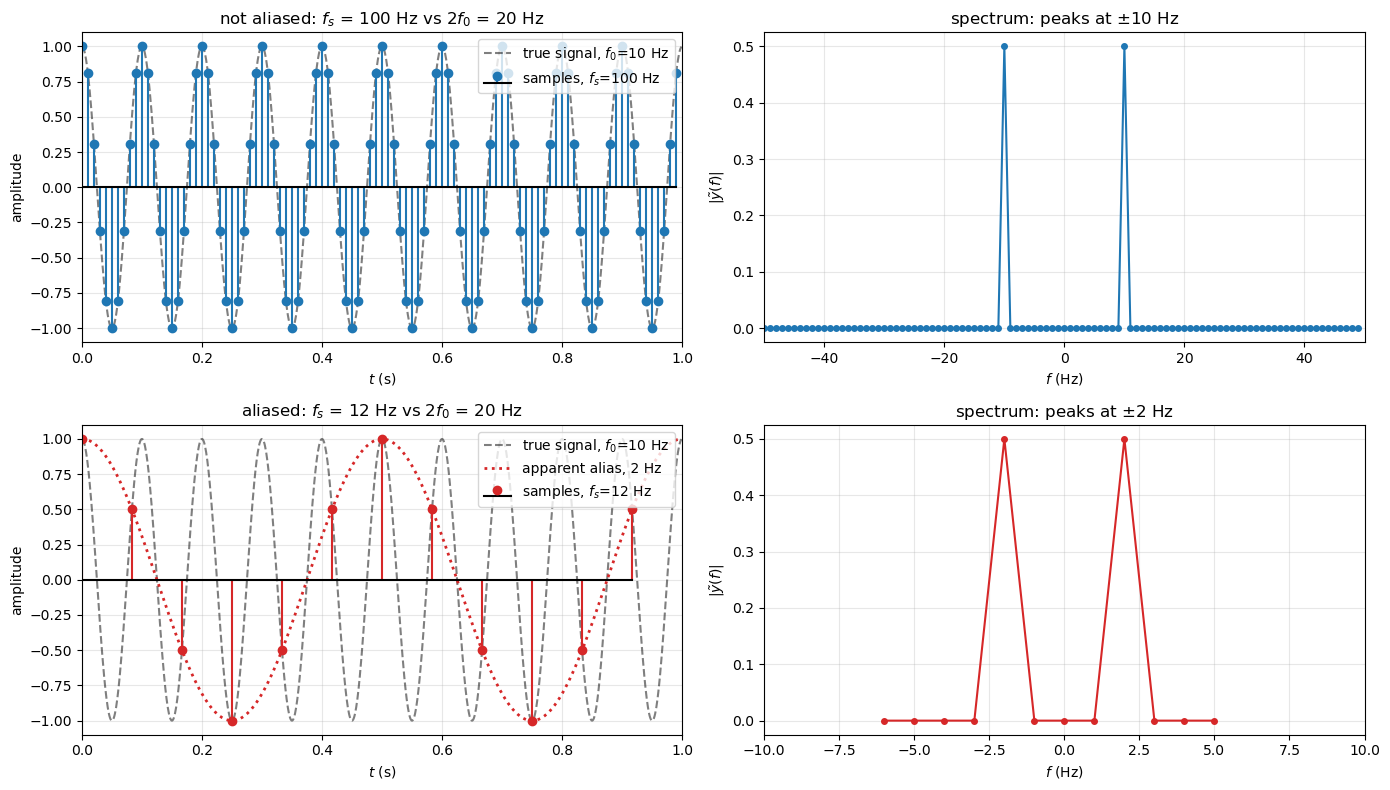

In [33]:
import numpy as np
import matplotlib.pyplot as plt

f0, T = 10.0, 1.0                                   # signal frequency (Hz), duration (s)
t_fine = np.linspace(0, T, 1000, endpoint=False)    # "continuous" reference
x = lambda t, f: np.cos(2*np.pi*f*t)

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
cases = [(100.0, 'C0', 50), (12.0, 'C3', 10)]       # (fs, colour, frequency-axis half-width)

for row, (fs, c, fmax) in enumerate(cases):
    N = int(fs*T)
    t = np.arange(N)/fs                             # exactly N samples (avoids arange float issues)
    y = x(t, f0)
    f = np.fft.fftshift(np.fft.fftfreq(N, 1/fs))
    Y = np.fft.fftshift(np.fft.fft(y))/N            # /N: a cosine gives peaks of 1/2 at +-f0

    f_alias = abs(f0 - fs*round(f0/fs))             # fold f0 into [0, fs/2]
    aliased = fs < 2*f0
    status = 'aliased' if aliased else 'not aliased'

    ax = axs[row, 0]
    ax.plot(t_fine, x(t_fine, f0), 'k--', alpha=0.5, label=rf'true signal, $f_0$={f0:g} Hz')
    if aliased:
        ax.plot(t_fine, x(t_fine, f_alias), c+':', lw=2, label=rf'apparent alias, {f_alias:g} Hz')
    ax.stem(t, y, linefmt=c, markerfmt=c+'o', basefmt='k-', label=rf'samples, $f_s$={fs:g} Hz')
    ax.set(title=rf'{status}: $f_s$ = {fs:g} Hz vs $2f_0$ = {2*f0:g} Hz', xlabel='$t$ (s)', ylabel='amplitude', xlim=(0, T))
    ax.legend(loc='upper right')

    ax = axs[row, 1]
    ax.plot(f, np.abs(Y), c+'-o', ms=4)
    peak = f[np.argmax(np.abs(Y))]
    ax.set(title=rf'spectrum: peaks at $\pm${abs(peak):g} Hz', xlabel='$f$ (Hz)', ylabel=r'$|\tilde{y}(f)|$', xlim=(-fmax, fmax))

for ax in axs.flat:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

1. Signal & Sampling Parameters:
   - Signal Frequency ($f_0$): $10\text{ Hz}$ ($\cos(2\pi \cdot 10 \cdot t)$)
   - Nyquist Rate ($2 f_0$): $20\text{ Hz}$
   - Non-Aliased Sampling Frequency ($f_{s, \text{good}}$): $100\text{ Hz}$ ($100\text{ Hz} > 20\text{ Hz}$)
   - Aliased Sampling Frequency ($f_{s, \text{bad}}$): $12\text{ Hz}$ ($12\text{ Hz} < 20\text{ Hz}$)

2. Are their Fourier transforms the same?
   No, they are NOT the same. Sampling at $100\text{ Hz}$ correctly identifies true spectral peaks at $f = \pm 10\text{ Hz}$. Sampling below the Nyquist rate at $12\text{ Hz}$ folds the $10\text{ Hz}$ frequency component into the fundamental Nyquist band $[-6, 6]\text{ Hz}$, producing false spectral peaks at $f_{\text{alias}} = |f_0 - f_s| = |10 - 12| = 2\text{ Hz}$.


**Problem 3: Code Summary**

Demonstrating Nyquist–Shannon aliasing by sampling a $10\text{ Hz}$ sinusoid above ($100\text{ Hz}$) and below ($12\text{ Hz}$) its $20\text{ Hz}$ Nyquist rate, comparing their time-domain reconstructions and FFT spectra. Vectorized NumPy arrays and `np.fft.fftfreq` calculate the discrete sample points and frequency axes, while `np.fft.fftshift` centers zero frequency for intuitive visualization. A $2 \times 2$ subplot structure is used to juxtapose the true signal, the discrete sample points, the apparent aliased wave, and the resulting spectral peak folding side-by-side.

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

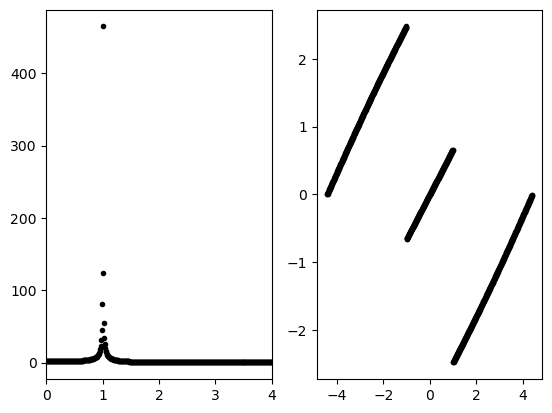

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

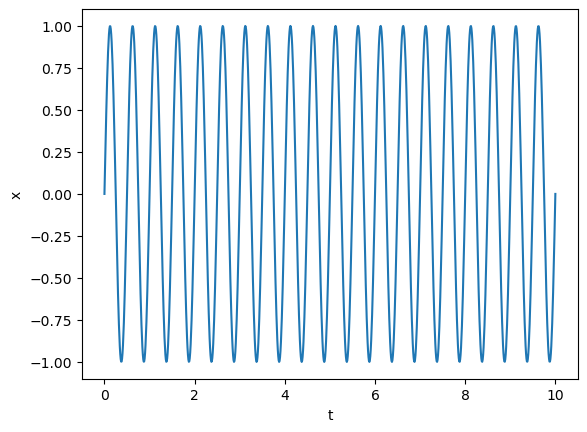

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

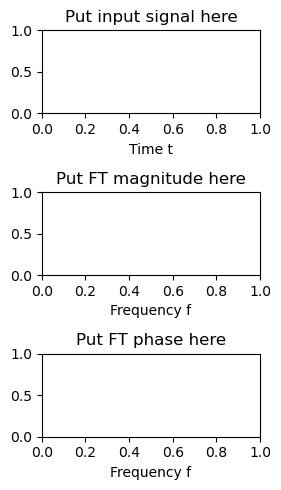

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

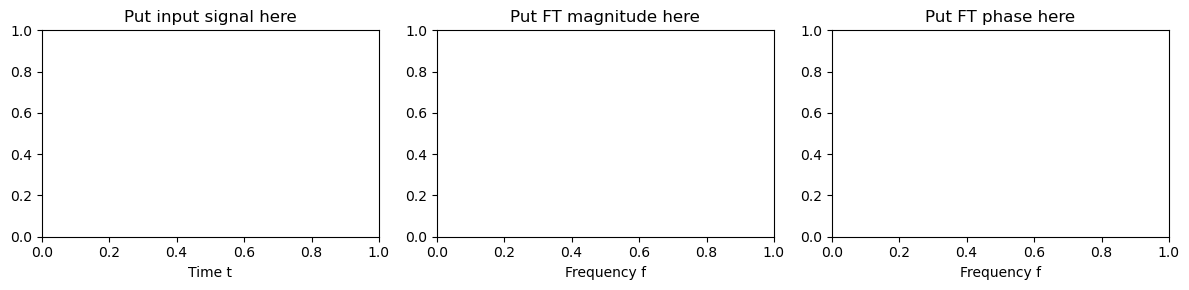

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

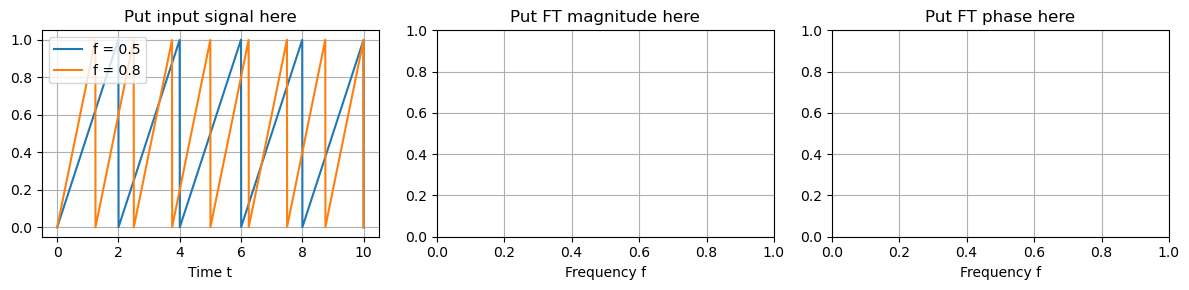

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



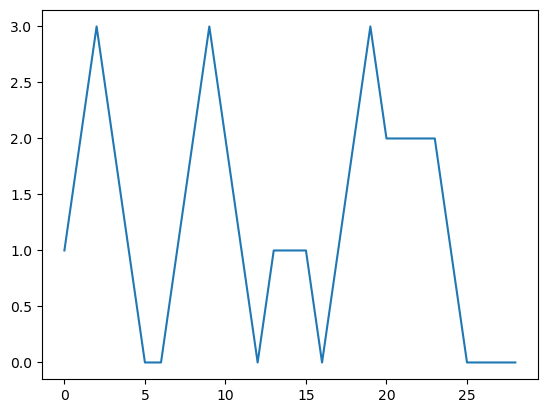

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

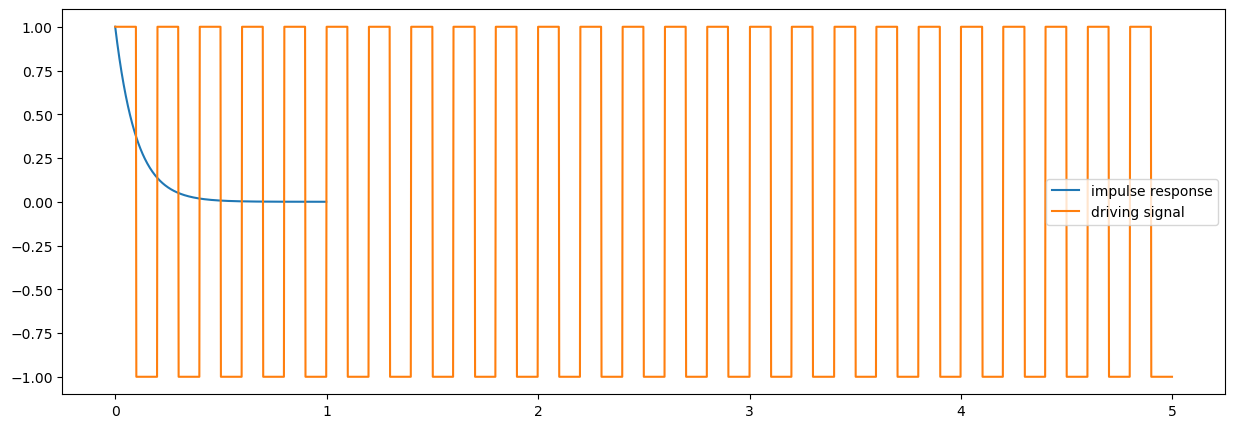

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

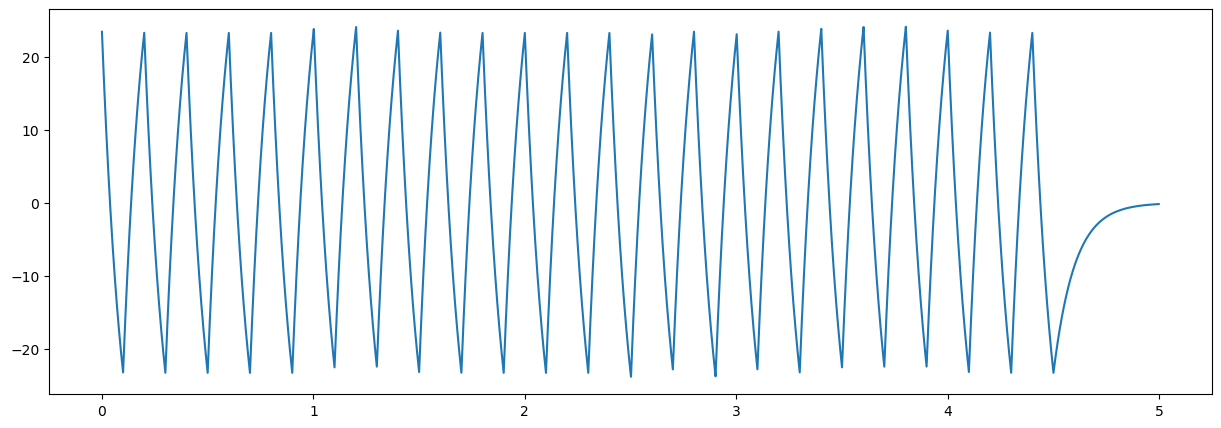

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

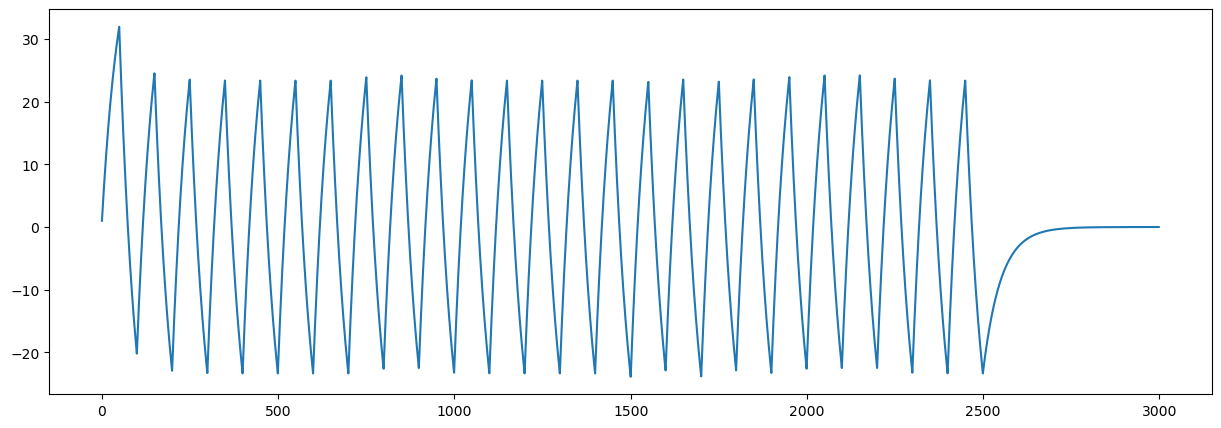

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)